In [47]:
#1.1 load and filter

import pandas as pd
import numpy as np

df = pd.read_csv('erasmus_flexipac350Y_hydraulics.csv')
data = df[df['packing'] == 'Flexipac 350Y'].copy()

pd.crosstab(df['packing'], df['system'])


system,air/Kerosol 200,air/water
packing,,
Flexipac 350Y,46,119
Flexipac 350Y HC,46,92


In [48]:
# delete null rows

dry = data[data['uL_m3_m2h'] == 0].copy()
static = data[data['uG_ms'] == 0].copy()

main = data[(data['uL_m3_m2h'] != 0) & (data['uG_ms'] != 0)].copy()
print(main.shape)

(139, 14)


In [49]:
# 1.3 forming curves

print(main.groupby(['system', 'uL_block']).ngroups)
print(main.groupby(['system', 'uL_m3_m2h']).ngroups)

main = main.sort_values(['system', 'uL_m3_m2h', 'F_Pa05']).reset_index(drop=True)
main.groupby(['system', 'uL_m3_m2h']).size()

# we can see the numebr of points falling on each of our 
# curves aand the holdup values that we have data for

12
10


system           uL_m3_m2h
air/Kerosol 200  6.1           9
                 12.7          9
                 20.6          8
                 28.8          8
                 35.6          7
air/water        6.0          16
                 12.9         20
                 20.5         21
                 28.8         21
                 35.6         20
dtype: int64

In [50]:
# 1.4 cleaning up curves and averging out repeats

dup = main.duplicated(subset = ['system', 'uL_m3_m2h', 'F_Pa05'], keep=False)
print(dup.sum())

# across all systems, we have 55 duplicates, deal with these later

# find and remove outliers with dp/dz that's more than 10% away

dpgroups = main.groupby(['system', 'uL_m3_m2h', 'F_Pa05'])['dPdz_Pa_m']
main['dp_sprd'] = 100 * (dpgroups.transform('max') - dpgroups.transform('min'))/ dpgroups.transform('mean')

agree = main[main['dp_sprd'] <= 10].copy()
disagree = main[main['dp_sprd'] > 10].copy()

# since the np.interp needs a 1-1 relationship, make each x have only one y

avg = agree.groupby(['system', 'uL_m3_m2h', 'F_Pa05']).agg(
    dpdz_Pa_m = ('dPdz_Pa_m', 'mean'),
    uG_ms = ('uG_ms', 'mean'),
    holdup = ('holdup_m3_m3', 'mean'),
    n = ('dPdz_Pa_m', 'count')
).reset_index()

print(pd.crosstab(avg['system'], avg['uL_m3_m2h']))
print(agree.shape), print(disagree.shape), print(avg.shape)
avg['n'].sum()


55
uL_m3_m2h        6.0   6.1   12.7  12.9  20.5  20.6  28.8  35.6
system                                                         
air/Kerosol 200     0     9     9     0     0     8     8     7
air/water          10     0     0    15    13     0    12    16
(131, 15)
(8, 15)
(107, 7)


np.int64(131)

In [51]:
# 1.5 Agree is used, disagree stored for later, when we apply physics model

disagree.to_csv('results/flexipac350Y_loading.csv', index=False)
disagree = disagree.rename(columns={'dPdz_Pa_m': 'dpdz_Pa_m', 'uG_ms': 'uG_ms', 'holdup_m3_m3': 'holdup'}) 
disagree['n'] = 1
curve = pd.concat([avg, disagree[avg.columns]])
curve = curve.sort_values(['system', 'uL_m3_m2h', 'F_Pa05']).reset_index(drop=True)

print(curve.shape)
curve['n'].sum()

(115, 7)


np.int64(139)

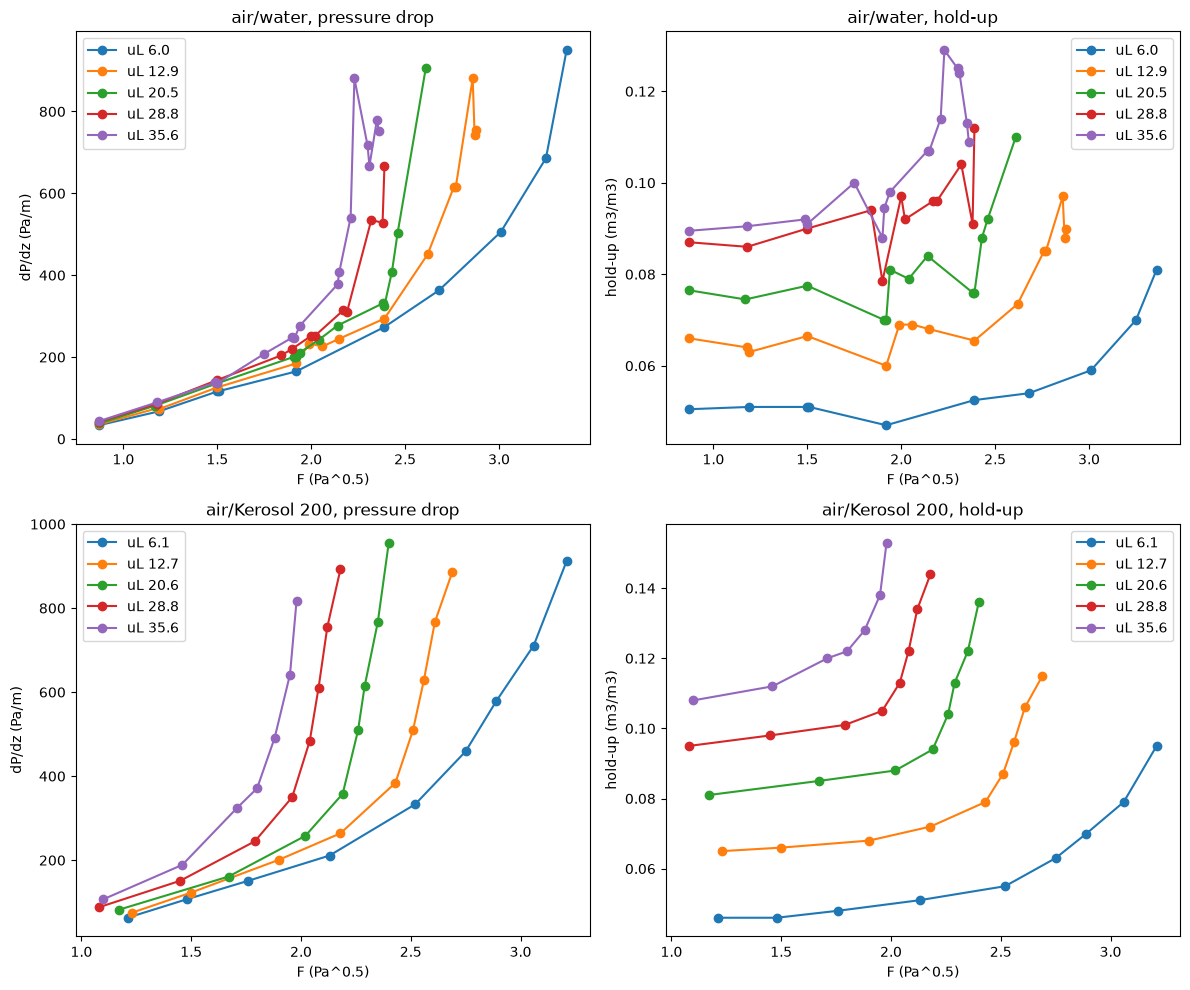

In [52]:
# 2.1 graph data

import matplotlib.pyplot as plt

fig, quads = plt.subplots(2, 2, figsize = (12,10))
for r, system in enumerate(['air/water', 'air/Kerosol 200']):
    sys= avg[avg['system'] == system]
    for uL in sys['uL_m3_m2h'].unique():
        curvey = sys[sys['uL_m3_m2h'] == uL]
        quads[r,0].plot(curvey['F_Pa05'], curvey['dpdz_Pa_m'], 'o-', label= 'uL ' + str(uL))
        quads[r,1].plot(curvey['F_Pa05'], curvey['holdup'], 'o-', label= 'uL ' + str(uL))
    quads[r, 0].set_title(system + ', pressure drop')
    quads[r, 1].set_title(system + ', hold-up')
    quads[r, 0].set_ylabel('dP/dz (Pa/m)')
    quads[r, 1].set_ylabel('hold-up (m3/m3)')
    for ax in quads[r]:
        ax.set_xlabel('F (Pa^0.5)')
        ax.legend()

plt.tight_layout()
plt.savefig('results/figures/flexipac350Y_data_curves.png', dpi=120)
plt.show()



In [53]:
# 2.3 read graphed data
c = avg[(avg['system'] =='air/water') & (avg['uL_m3_m2h'] == 28.8)]

print(c)
np.interp(1.9, c['F_Pa05'], c['dpdz_Pa_m'])

# all good!

       system  uL_m3_m2h  F_Pa05   dpdz_Pa_m  uG_ms  holdup  n
79  air/water       28.8    0.87   42.000000  0.805  0.0870  2
80  air/water       28.8    1.18   86.333333  1.090  0.0860  3
81  air/water       28.8    1.50  144.000000  1.390  0.0900  2
82  air/water       28.8    1.84  204.000000  1.700  0.0940  1
83  air/water       28.8    1.90  220.500000  1.750  0.0785  2
84  air/water       28.8    2.00  252.000000  1.850  0.0970  1
85  air/water       28.8    2.02  252.000000  1.870  0.0920  1
86  air/water       28.8    2.17  314.000000  2.000  0.0960  1
87  air/water       28.8    2.19  309.000000  2.020  0.0960  1
88  air/water       28.8    2.32  535.000000  2.140  0.1040  1
89  air/water       28.8    2.38  528.000000  2.190  0.0910  1
90  air/water       28.8    2.39  667.000000  2.210  0.1120  2


np.float64(220.5)

In [54]:
# 2.4 testing interp between 2 lines now for one random point

# try and get pressure drop for uL 25

point = 25

s = avg[avg['system'] == 'air/water']
uLs = np.sort(s['uL_m3_m2h'].unique())

below = uLs[uLs <= point].max()
above = uLs[uLs >= point].min()

hup_low = s[s['uL_m3_m2h'] == below]
hup_high = s[s['uL_m3_m2h'] == above]
dplow = np.interp(1.5, hup_low['F_Pa05'], hup_low['dpdz_Pa_m'])
dphigh = np.interp(1.5, hup_high['F_Pa05'], hup_high['dpdz_Pa_m'])

w = (point - below)/(above - below)
dp = dplow + w * (dphigh - dplow)

print(uLs), print(below, above), print(dplow, dphigh), print(dp)

[ 6.  12.9 20.5 28.8 35.6]
20.5 28.8
136.0 144.0
140.33734939759037


(None, None, None, None)

In [55]:
# 2.5 generalising to a function

# using system, uL, F, return dpdz and holdup

def predict(system, uL, F, table):
    s = table[table['system'] == system]
    uLs = np.sort(s['uL_m3_m2h'].unique())
    
    if not(uLs.min() <= uL <= uLs.max()):
     return np.nan, np.nan, True

    below = uLs[uLs <= uL].max()
    above = uLs[uLs >= uL].min()
    hup_low = s[s['uL_m3_m2h'] == below]
    hup_high = s[s['uL_m3_m2h'] == above]

    F_ok = (hup_low['F_Pa05'].min() <= F <= hup_low['F_Pa05'].max()) and (hup_high['F_Pa05'].min() <= F <= hup_high['F_Pa05'].max())

    if not F_ok:
        return np.nan, np.nan, True

    dplow = np.interp(F, hup_low['F_Pa05'], hup_low['dpdz_Pa_m'])
    dphigh = np.interp(F, hup_high['F_Pa05'], hup_high['dpdz_Pa_m'])
    holdup_low = np.interp(F, hup_low['F_Pa05'], hup_low['holdup'])
    holdup_high = np.interp(F, hup_high['F_Pa05'], hup_high['holdup'])

    if below == above:
       w = 0
    else:
         w = (uL - below)/(above - below)
    dp = dplow + w * (dphigh - dplow)
    holdup = holdup_low + w * (holdup_high - holdup_low)

    return float(dp), float(holdup), False



In [56]:
# 2.6 outputs, testing if this function works and if it flags

print(predict('air/water', 28.8, 1.5, avg))
print(predict('air/water', 25, 1.5, avg))
print(predict('air/Kerosol 200', 10, 2.0, avg))
print(predict('air/water', 25, 5, avg))
print(predict('air/water', 50, 1.5, avg))

(144.0, 0.09, False)
(140.33734939759037, 0.08427710843373494, False)
(209.76228501228502, 0.06145840645840646, False)
(nan, nan, True)
(nan, nan, True)


In [57]:
# 3.1 checking one point

test = avg.loc[70]
train = avg.drop(70)

print(test['system'], test['uL_m3_m2h'], test['F_Pa05'])
print(test['dpdz_Pa_m'], test['holdup'])

predict(test['system'], test['uL_m3_m2h'], test['F_Pa05'], train)


air/water 20.5 1.92
201.0 0.07


(204.33333333333334, 0.07366666666666667, False)

In [58]:
# Now define a function to calculate the error

def score(test, train):
    results =[]
    for i in test.index:
        testrow = test.loc[i]
        dp, holdup, flag = predict(testrow['system'], testrow['uL_m3_m2h'], testrow['F_Pa05'], train)
        dp_err = 100* abs(dp - testrow['dpdz_Pa_m'])/testrow['dpdz_Pa_m']
        holdup_err = 100* abs(holdup - testrow['holdup'])/testrow['holdup']
        results.append([i, dp_err, holdup_err])
    return pd.DataFrame(results, columns=['testrow', 'dp_err', 'holdup_err'])

score(avg.loc[[70]], avg.drop(70))

,testrow,dp_err,holdup_err
0,70,1.658375,5.238095


In [59]:
# 3.2 test each point by exclusion

parts = []
for i in avg.index:
    testpart = score(avg.loc[[i]], avg.drop(i))
    parts.append(testpart)
exclusions = pd.concat(parts)

print(exclusions.shape)
print(exclusions['dp_err'].notna().sum())



(107, 3)
87


In [60]:
# test interpolation by curve exclusion

parts2 = []
for name, curverows in avg.groupby(['system', 'uL_m3_m2h']):
    testpart2 = score(curverows, avg.drop(curverows.index))
    parts2.append(testpart2)
curveout = pd.concat(parts2)

print(curveout.shape)
print(curveout['dp_err'].notna().sum())

(107, 3)
38


In [61]:
# 3.4 test interpolation function on a new system

train = avg[avg['system'] == 'air/water']
test = avg[avg['system'] == 'air/Kerosol 200'].copy()

# the test rows try to map to corresponding train rows, 
# but Kerosol doesn't have the same values in the system column

test['system'] = 'air/water'

trainw_to_k = score(test, train)
print(trainw_to_k.shape)
print(trainw_to_k['dp_err'].notna().sum())


(41, 3)
37


In [62]:
# 3.5 train on lower F values, test on higher - "Top F test"
train = avg[avg['F_Pa05'] < 2.0]
test = avg[avg['F_Pa05'] >= 2.0]

top_f = score(test, train)
print(top_f.shape)
print(top_f['dp_err'].notna().sum())

# since we are interpolating, not extrapolating, no results

(58, 3)
0


In [63]:
# 3.6 summary of tests and errors

errorrows = []
for name, r in [('leave one point out', exclusions), ('leave one curve out', curveout), ('train water, test kerosol', trainw_to_k), ('top F test', top_f)]:
    errorrows.append([name, len(r), r['dp_err'].notna().sum(), r['dp_err'].mean(), r['holdup_err'].mean()])
error_table = pd.DataFrame(errorrows, columns = ['split', 'tested', 'answered', 'dp_err_%', 'hold_err_%'])
error_table

,split,tested,answered,dp_err_%,hold_err_%
0,leave one point out,107,87,7.501722,4.028799
1,leave one curve out,107,38,8.258960,3.850444
2,"train water, test kerosol",41,37,27.490657,17.062442
3,top F test,58,0,NaN,NaN


In [64]:
# 3.7 packaging all 4 tests to apply to other methods

splits = {}

pairs = []
for i in avg.index:
    pairs.append((avg.drop(i), avg.loc[[i]]))
splits['leave one point out'] = pairs

pairs = []
for name, curve_rows in avg.groupby(['system', 'uL_m3_m2h']):
    pairs.append((avg.drop(curve_rows.index), curve_rows))
splits['leave one curve out'] = pairs

splits['train water, test kerosol'] = [(avg[avg['system'] == 'air/water'], avg[avg['system'] == 'air/Kerosol 200'])]
splits['top F test'] = [(avg[avg['F_Pa05'] < 2.0], avg[avg['F_Pa05'] >= 2.0])]

for name in splits:
    print(name, len(splits[name]))

leave one point out 107
leave one curve out 10
train water, test kerosol 1
top F test 1


In [65]:
# turning it into one big run function

def run(method,pairs):
    parts = []
    for train, test in pairs:
        parts.append(method(train, test))
    out = pd.concat(parts)

    out['dp_true'] = avg.loc[out.index, 'dpdz_Pa_m']
    out['holdup_true'] = avg.loc[out.index, 'holdup']
    out['dp_err'] = 100 * (out['dp_pred'] - out['dp_true']).abs() / out['dp_true']
    out['holdup_err'] = 100 * (out['hold_pred'] - out['holdup_true']).abs() / out['holdup_true']
    return out

In [66]:
# 3.8 interpolation as a method, so run() can use it, then a check on leave one out
def interp_method(train, test):
    results = []
    for i in test.index:
        row = test.loc[i]
        system = row['system']
        if system not in train['system'].values:
            system = train['system'].iloc[0]
        dp, hold, flag = predict(system, row['uL_m3_m2h'], row['F_Pa05'], train)
        results.append([dp, hold])
    return pd.DataFrame(results, columns=['dp_pred', 'hold_pred'], index=test.index)

out = run(interp_method, splits['leave one point out'])
print(out['dp_pred'].notna().sum(), out['dp_err'].mean())


87 7.501721647903061


In [67]:
# 4.0 Billet Constants

# packing constants for flexipac 350Y from erasmus table 7.3
# erasmus fitted Cp 0.172 with the wall factor multiplied. billet divides (D13a),
# so converting by fs squared keeps erasmus's predictions exactly the same
fs_erasmus = 1 / (1 + 4 / (350 * 0.2))
C_erasumus = {'Cp': 0.172 * fs_erasmus ** 2, 'Clp': 3.157, 'Cfp': 2.464, 'Ch': 0.482}


# packing and column, void fraction from erasmus table 4.2, column is 200 mm
ap = 350 # packing area per volume
eps = 0.985 # void frac
dc = 0.2 # column diameter
g = 9.81 #grav

# fluid properties from erasmus table 4.1, density in kg/m3, viscosity in Pa.s
rho_G = 1.15
mu_G = 1.86e-5
rho_W = 1000
mu_W = 8.02e-4
props = {'air/water': (1000, 8.02e-4), 'air/Kerosol 200': (763, 2.31e-3)}


In [68]:
# 4.1 Dry pressure drop

# let the test point be uL = 6.9 and F = 1.9

system = 'air/water'
uL_s = 6.0 / 3600
uG_s = 1.9 / np.sqrt(rho_G)
rho_L, mu_L = props[system]

# particle diameter and wall factor (narrow column)
d_part = 6 * (1 - eps) / ap
fs = 1 / (1 + 4 / (ap * dc))

# Reynolds, Friction Factor and then dry dpdz calc

Re_G = uG_s * d_part * rho_G / ((1 - eps) * mu_G) * fs
xi_d = C_erasumus['Cp'] * (64 / Re_G + 1.8 / Re_G ** 0.08)
dp_dry = xi_d * ap / eps ** 3 * uG_s ** 2 / 2 * rho_G / fs  # billet divides by the wall factor (D13a)

print(d_part, fs)
print(Re_G, dp_dry)

0.00025714285714285737 0.9459459459459459
1776.393204886735 110.27477779677265


In [69]:
# 4.2 introduce liquid loading

# flow parameter, liquid to gas ratio
psi = (uL_s * rho_L) / (uG_s * rho_G) * np.sqrt(rho_G / rho_L)

# hold-up at loading point first - empirical
ht_lp = 12 ** (1/3) * (uL_s * rho_L / (ap * mu_L)) ** (-1/3) * (uL_s ** 2 * ap / g) ** (1/3)

# according to how the emp relation created, exponents switch at psi 0.4
if psi <= 0.4:
    n_lp = -0.326
    n_fp = -0.194
else:
    n_lp = -0.723
    n_fp = -0.708

xi_lp = g / (C_erasumus['Clp'] ** 2 * (psi * (mu_L / mu_G) ** 0.4) ** (2 * n_lp))
uG_lp = np.sqrt(g / xi_lp) * (eps - ht_lp) * np.sqrt(ht_lp / ap) * np.sqrt(rho_L / rho_G)

# flood point, hold-up at flood point
ht_fp = 0.3741 * eps * (mu_L * rho_W / (rho_L * mu_W)) ** 0.05
xi_fp = g / (C_erasumus['Cfp'] ** 2 * (psi * (mu_L / mu_G) ** 0.2) ** (2 * n_fp))
uG_fp = np.sqrt(2 * g / xi_fp) * (eps - ht_fp) ** 1.5 / np.sqrt(eps) * np.sqrt(ht_fp / ap) * np.sqrt(rho_L / rho_G)

# printing as F so it matches the data
print(psi)
print(uG_lp * np.sqrt(rho_G), uG_fp * np.sqrt(rho_G))

0.027739277720775266
2.3555088052665263 3.0209391969585777


In [70]:
# 4.3 stage 3, hold-up, one equation above and below. two hold-ups:
# ht_dp goes into the pressure drop, from loading to flood hold-up past the loading point (4.3.2)
if uG_s <= uG_lp:
    ht_dp = ht_lp
else:
    ht_dp = ht_lp + (ht_fp - ht_lp) * (uG_s / uG_fp) ** 13

# holdup is the one we compare with the data, partial wetting (4.3.1), formula switches at Re_L 5
Re_L = uL_s * rho_L / (ap * mu_L)
Fr_L = uL_s ** 2 * ap / g
if Re_L < 5:
    ah_ap = C_erasumus['Ch'] * Re_L ** 0.15 * Fr_L ** 0.1
else:
    ah_ap = 0.85 * C_erasumus['Ch'] * Re_L ** 0.25 * Fr_L ** 0.1


ht_lp2 = (12 * mu_L * ap ** 2 * uL_s / (rho_L * g)) ** (1/3) * ah_ap ** (2/3)
ht_fp2 = 2.2 * ht_lp2
if uG_s <= uG_lp:
    holdup = ht_lp2
else:
    holdup = ht_lp2 + (ht_fp2 - ht_lp2) * (uG_s / uG_fp) ** 13

print(ht_dp, holdup)

0.058509153530788977 0.023489581699613214


In [71]:
# 4.4 stage 4, wet pressure drop = dry x a liquid factor, W is the correction for the liquid

W = np.exp(Re_L / 200) * (ht_dp / ht_lp) ** 0.3
xi_w = C_erasumus['Cp'] * W * (64 / Re_G + 1.8 / Re_G ** 0.08) * ((eps - ht_dp) / eps) ** 1.5
dp_wet = dp_dry * (xi_w / xi_d) * (eps / (eps - ht_dp)) ** 3

print(W)
print(dp_dry, dp_wet)

1.0301327583606694
110.27477779677265 124.52657280560965


In [72]:
# Billet function

# note the inputs must be uL in m3/m2h and and Gas Velocity in m/s, not F

def billet (system, uL, uG_s, C=C_erasumus):
    # properties
    rho_L, mu_L = props[system]
    uL_s = uL / 3600

    # particle diameter, wall factor, flow parameter
    d_part = 6 * (1 - eps) / ap
    fs = 1 / (1 + 4 / (ap * dc))
    psi = (uL_s * rho_L) / (uG_s * rho_G) * np.sqrt(rho_G / rho_L)

    # loading point limit

    ht_lp = 12 ** (1/3) * (uL_s * rho_L / (ap * mu_L)) ** (-1/3) * (uL_s ** 2 * ap / g) ** (1/3)
    if psi <= 0.4:
        n_lp = -0.326
        n_fp = -0.194
    else:
        n_lp = -0.723
        n_fp = -0.708
    
    xi_lp = g / (C['Clp'] ** 2 * (psi * (mu_L / mu_G) ** 0.4) ** (2 * n_lp))
    uG_lp = np.sqrt(g / xi_lp) * (eps - ht_lp) * np.sqrt(ht_lp / ap) * np.sqrt(rho_L / rho_G)

    # cap when flooding - flood point

    ht_fp = 0.3741 * eps * (mu_L * rho_W / (rho_L * mu_W)) ** 0.05
    xi_fp = g / (C['Cfp'] ** 2 * (psi * (mu_L / mu_G) ** 0.2) ** (2 * n_fp))
    uG_fp = np.sqrt(2 * g / xi_fp) * (eps - ht_fp) ** 1.5 / np.sqrt(eps) * np.sqrt(ht_fp / ap) * np.sqrt(rho_L / rho_G)

    # no answer past the flood point
    if uG_s > uG_fp:
        return np.nan, np.nan
    
    # hold-up for the pressure drop
    if uG_s <= uG_lp:
        ht_dp = ht_lp
    else:
        ht_dp = ht_lp + (ht_fp - ht_lp) * (uG_s / uG_fp) ** 13

    # hold-up we compare with the data
    Re_L = uL_s * rho_L / (ap * mu_L)
    Fr_L = uL_s ** 2 * ap / g
    
    if Re_L < 5:
        ah_ap = C['Ch'] * Re_L ** 0.15 * Fr_L ** 0.1
    else:
        ah_ap = 0.85 * C['Ch'] * Re_L ** 0.25 * Fr_L ** 0.1
    
    ht_lp2 = (12 * mu_L * ap ** 2 * uL_s / (rho_L * g)) ** (1/3) * ah_ap ** (2/3)
    ht_fp2 = 2.2 * ht_lp2
    
    if uG_s <= uG_lp:
        holdup = ht_lp2
    else:
        holdup = ht_lp2 + (ht_fp2 - ht_lp2) * (uG_s / uG_fp) ** 13

    # dry and wet pressure drop
    Re_G = uG_s * d_part * rho_G / ((1 - eps) * mu_G) * fs
    xi_d = C['Cp'] * (64 / Re_G + 1.8 / Re_G ** 0.08)
    
    dp_dry = xi_d * ap / eps ** 3 * uG_s ** 2 / 2 * rho_G / fs  # billet divides by the wall factor (D13a)
    W = np.exp(Re_L / 200) * (ht_dp / ht_lp) ** 0.3
    xi_w = C['Cp'] * W * (64 / Re_G + 1.8 / Re_G ** 0.08) * ((eps - ht_dp) / eps) ** 1.5
   
    dp_wet = dp_dry * (xi_w / xi_d) * (eps / (eps - ht_dp)) ** 3

    return float(dp_wet), float(holdup)
    

In [73]:
# 4.6 check against the billet points in erasmus figures 4.12 to 4.15, (roughly read off by eye)

# uL 6.0, F 1.9 about 130 Pa/m, F 2.4 about 200, F 3.0 about 480, hold-up flat at about 0.024
# uL 35.7, F 1.5 about 100 Pa/m, hold-up flat at about 0.074
print(billet('air/water', 6.0, 1.9 / np.sqrt(rho_G)))
print(billet('air/water', 6.0, 2.4 / np.sqrt(rho_G)))
print(billet('air/water', 6.0, 3.0 / np.sqrt(rho_G)))
print(billet('air/water', 35.7, 1.5 / np.sqrt(rho_G)))
print(billet('air/water', 35.7, 3.0 / np.sqrt(rho_G)))

(124.52657280560965, 0.023489581699613214)
(193.68642961540854, 0.023489581699613214)
(454.930994103292, 0.03162732193396484)
(99.99035287131461, 0.07267795431281822)
(nan, nan)


In [74]:
# now run this on all the points
results = []
for i in curve.index:
    row = curve.loc[i]
    dp_b, holdup_b = billet(row['system'], row['uL_m3_m2h'], row['uG_ms'])
    results.append([dp_b, holdup_b])

billet_out = pd.DataFrame(results, columns = ['dp_billet', 'holdup_billet'], index = curve.index)
baseline = pd.concat([curve, billet_out], axis = 1)

baseline['dp_err'] = 100 * (baseline['dp_billet'] - baseline['dpdz_Pa_m']) / baseline['dpdz_Pa_m']
baseline['holdup_err'] = 100 * (baseline['holdup_billet'] - baseline['holdup']) / baseline['holdup']


print(baseline['dp_billet'].notna().sum())
print(baseline.shape)
baseline.head(2)

75
(115, 11)


,system,uL_m3_m2h,F_Pa05,dpdz_Pa_m,uG_ms,holdup,n,dp_billet,holdup_billet,dp_err,holdup_err
0,air/Kerosol 200,6.1,1.21,63.0,1.12,0.046,1,54.329730,0.031992,-13.762333,-30.452958
1,air/Kerosol 200,6.1,1.48,107.0,1.37,0.046,1,79.279132,0.031992,-25.907354,-30.452958


In [75]:
# 4.7 summary by system and F band, 
# mean abs error and bias in percent, 
# how many got an answer?

baseline['dp_abs_err'] = baseline['dp_err'].abs()
baseline['holdup_abs_err'] = baseline['holdup_err'].abs()
baseline['F_band'] = np.where(baseline['F_Pa05'] < 2.0, 'F below 2', 'F 2 and above')

baseline.groupby(['system', 'F_band']).agg(
    tested=('dp_err', 'size'),
    answered=('dp_billet', 'count'),
    dp_abs_err=('dp_abs_err', 'mean'),
    dp_bias=('dp_err', 'mean'),
    hold_abs_err=('holdup_abs_err', 'mean'),
    hold_bias=('holdup_err', 'mean')
).round(1)


tested  answered  dp_abs_err  dp_bias  \
system          F_band                                                 
air/Kerosol 200 F 2 and above      22         4        25.8     13.4   
                F below 2          19        14        31.5    -31.5   
air/water       F 2 and above      44        27        13.0     -9.5   
                F below 2          30        30        27.0    -27.0   

                               hold_abs_err  hold_bias  
system          F_band                                  
air/Kerosol 200 F 2 and above          31.1        8.3  
                F below 2              25.4      -14.5  
air/water       F 2 and above          24.2      -12.0  
                F below 2              30.5      -30.5

In [76]:
# 5.0 check billet function can take any inputs

# with erasmus own constants
print(billet('air/water', 6.0, 1.9 / np.sqrt(rho_G), C_erasumus))

# change the value of one of the constants, CH
C_test = dict(C_erasumus)
C_test['Ch'] = 0.9
print(billet('air/water', 6.0, 1.9 / np.sqrt(rho_G), C_test))


(124.52657280560965, 0.023489581699613214)
(124.52657280560965, 0.0356182242414269)


In [77]:
# another tiny fix to allow billet to run at all uLs

def dry_dp(uG_s, C = C_erasumus):
    d_part = 6 * (1 - eps) / ap
    fs = 1 / (1 + 4 / (ap * dc))
    Re_G = uG_s * d_part * rho_G / ((1 - eps) * mu_G) * fs
    xi_d = C['Cp'] * (64 / Re_G + 1.8 / Re_G ** 0.08)
    return xi_d * ap / eps ** 3 * uG_s ** 2 / 2 * rho_G / fs  # billet divides by the wall factor (D13a)

print(dry_dp(1.9 / np.sqrt(rho_G), C_erasumus))


110.27477779677265


In [78]:
# 5.1 error optimiser for parameter estimation level 1 model

from scipy.optimize import minimize_scalar, minimize

def log_error (pred, measured, penalty = 1):
    pred = np.array(pred, dtype=float)
    measured = np.array(measured, dtype=float)
    sq = np.log(pred / measured) ** 2
    sq[np.isnan(sq)] = penalty
    return sq.sum()

# check if it works

print(log_error([60], [50]), log_error([600], [500]))
print(log_error([120, 60], [100, 50]))
print(log_error([np.nan, 120], [100, 100]))



0.03324115007177121 0.03324115007177121
0.06648230014354242
1.0332411500717713


In [79]:
# 5.2 fit Cp and use the dry rows to do this, since Cp is the only switch on these rows

dry['dp_0'] = dry_dp(dry['uG_ms'], C_erasumus)
dry['err_0'] = 100 * (dry['dp_0'] - dry['dPdz_Pa_m']) / (dry['dPdz_Pa_m'])
print(dry[['F_Pa05', 'dPdz_Pa_m', 'dp_0', 'err_0']].round(1))

# create the score for Cp candidates

def cp_score (Cp, rows):
    pred = dry_dp(rows['uG_ms'], {'Cp': Cp})
    return log_error(pred, rows['dPdz_Pa_m'])

# there's an outlier at F=0.8, let's discard that and proceed with Cp

for name, rows in [('all 11 rows', dry), ('without F 0.84', dry.drop(dry['F_Pa05'].idxmin()))]:
    fit = minimize_scalar(cp_score, bounds=(0.01,1.0), method = 'bounded', args=(rows,))
    pred = dry_dp(rows['uG_ms'], {'Cp': fit.x})
    err = 100 * (pred - rows['dPdz_Pa_m']).abs() / rows['dPdz_Pa_m']
    exact = C_erasumus['Cp'] * np.exp(-np.mean(np.log(dry_dp(rows['uG_ms'], C_erasumus) / rows['dPdz_Pa_m'])))
    print(name, '| Cp =', round(fit.x, 4), '| exact =', round(exact, 4), '| converged:', fit.success, '| mean abs error %:', round(err.mean(), 1))
    

     F_Pa05  dPdz_Pa_m   dp_0  err_0
108     0.8        8.0   23.2  189.6
109     1.2       38.0   44.3   16.4
110     1.5       72.0   70.8   -1.7
111     1.9      112.0  112.4    0.4
112     2.4      146.0  161.8   10.8
113     2.4      171.0  163.2   -4.6
114     2.7      223.0  213.2   -4.4
115     3.0      272.0  257.0   -5.5
116     3.0      252.0  258.8    2.7
117     3.5      347.0  342.1   -1.4
118     3.9      416.0  411.8   -1.0
all 11 rows | Cp = 0.1385 | exact = 0.1385 | converged: True | mean abs error %: 23.6
without F 0.84 | Cp = 0.1525 | exact = 0.1525 | converged: True | mean abs error %: 5.2


In [80]:
C_fit = dict(C_erasumus)
C_fit['Cp'] = minimize_scalar(cp_score, bounds=(0.01, 1.0), method='bounded', args=(dry.drop(dry['F_Pa05'].idxmin()),)).x
print(C_fit)


{'Cp': np.float64(0.1524552552955921), 'Clp': 3.157, 'Cfp': 2.464, 'Ch': 0.482}


In [81]:
# 5.3 stage B, fit Ch on the calm zone holdup


def loading_uG(system, uL, uG_s, C):
    rho_L, mu_L = props[system]
    uL_s = uL / 3600
    psi = (uL_s * rho_L) / (uG_s * rho_G) * np.sqrt(rho_G / rho_L)
    ht_lp = 12 ** (1/3) * (uL_s * rho_L / (ap * mu_L)) ** (-1/3) * (uL_s ** 2 * ap / g) ** (1/3)
    if psi <= 0.4:
        n_lp = -0.326
    else:
        n_lp = -0.723
    xi_lp = g / (C['Clp'] ** 2 * (psi * (mu_L / mu_G) ** 0.4) ** (2 * n_lp))
    return np.sqrt(g / xi_lp) * (eps - ht_lp) * np.sqrt(ht_lp / ap) * np.sqrt(rho_L / rho_G)

lp = []
for i in curve.index:
    row = curve.loc[i]
    lp.append(loading_uG(row['system'], row['uL_m3_m2h'], row['uG_ms'], C_fit))

calm = curve[curve['uG_ms'] <= np.array(lp)]
print(len(calm))
print(calm.groupby('system').size())


35
system
air/Kerosol 200    12
air/water          23
dtype: int64


In [82]:
def billet_rows(rows, C):
    results = []
    for i in rows.index:
        row = rows.loc[i]
        results.append(billet(row['system'], row['uL_m3_m2h'], row['uG_ms'], C))
    return pd.DataFrame(results, columns=['dp', 'hold'], index=rows.index)

# the score for one trial Ch
def ch_score(Ch, rows):
    C = dict(C_fit)
    C['Ch'] = Ch
    return log_error(billet_rows(rows, C)['hold'], rows['holdup'])

# fit Ch separately for each liquid (D31). C_lib holds one set of constants per liquid system
C_lib = {}
for system in ['air/water', 'air/Kerosol 200']:
    rows = calm[calm['system'] == system]
    fit = minimize_scalar(ch_score, bounds=(0.05, 3.0), method='bounded', args=(rows,))
    C_lib[system] = dict(C_fit)
    C_lib[system]['Ch'] = fit.x
    before = billet_rows(rows, C_erasumus)['hold']
    after = billet_rows(rows, C_lib[system])['hold']
    exact = 0.482 * np.exp(-1.5 * np.mean(np.log(before / rows['holdup'])))
    for name, h in [('erasmus Ch', before), ('fitted Ch', after)]:
        err = 100 * (h - rows['holdup']) / rows['holdup']
        print(system, '|', name, '| mean abs error %:', round(err.abs().mean(), 1), '| bias %:', round(err.mean(), 1))
    print(system, '| Ch =', round(fit.x, 4), '| exact =', round(exact, 4), '| converged:', fit.success, '| rows:', len(rows))


air/water | erasmus Ch | mean abs error %: 37.9 | bias %: -37.9
air/water | fitted Ch | mean abs error %: 17.0 | bias %: 1.9
air/water | Ch = 1.0145 | exact = 1.0145 | converged: True | rows: 23
air/Kerosol 200 | erasmus Ch | mean abs error %: 25.8 | bias %: -25.8
air/Kerosol 200 | fitted Ch | mean abs error %: 7.2 | bias %: 0.4
air/Kerosol 200 | Ch = 0.7588 | exact = 0.7588 | converged: True | rows: 12


In [83]:
# 5.4 Cfp

# for Cp we were able to isolate using the dry rows. Obj fn was dPdz
# for Ch we were able to isolate using calm zone. Obj fn was holdup
# here Cfp affects both obj fns and has no one isolation zone

# so first we define the area bounds where this is valid - which is the loading zone


def flood_uG(system, uL, uG_s, C):
    rho_L, mu_L = props[system]
    uL_s = uL / 3600
    psi = (uL_s * rho_L) / (uG_s * rho_G) * np.sqrt(rho_G / rho_L)
    if psi <= 0.4:
        n_fp = -0.194
    else:
        n_fp = -0.708
    ht_fp = 0.3741 * eps * (mu_L * rho_W / (rho_L * mu_W)) ** 0.05
    xi_fp = g / (C['Cfp'] ** 2 * (psi * (mu_L / mu_G) ** 0.2) ** (2 * n_fp))
    return np.sqrt(2 * g / xi_fp) * (eps - ht_fp) ** 1.5 / np.sqrt(eps) * np.sqrt(ht_fp / ap) * np.sqrt(rho_L / rho_G)

# boundary is determined by the lowest point. To find this point, we 
# need the level where measured gas speed is billet flood speed and their ratio is 1

#hence, finding the ratio that has valid results at highest velocity (not flooding)
Cfp_min = {}
for system in ['air/water', 'air/Kerosol 200']:
    rows = curve[curve['system'] == system]
    ratio = []
    for i in rows.index:
        row = rows.loc[i]
        ratio.append(row['uG_ms'] / flood_uG(row['system'], row['uL_m3_m2h'], row['uG_ms'], C_lib[system]))
    Cfp_min[system] = C_lib[system]['Cfp'] * max(ratio)
    print(system, '| worst ratio =', round(max(ratio), 4), '| Cfp_min =', round(Cfp_min[system], 4))


air/water | worst ratio = 1.0462 | Cfp_min = 2.5778
air/Kerosol 200 | worst ratio = 1.1483 | Cfp_min = 2.8294


In [84]:
# now define the cfp score and minimise least squares in the same way 
# but now we also need ot make sure we are within the floor

def cfp_score(Cfp, rows, outputs, base):
    C = dict(base)
    C['Cfp'] = Cfp
    pred = billet_rows(rows, C)
    score = 0
    if 'dp' in outputs:
        score = score + log_error(pred['dp'], rows['dpdz_Pa_m'])
    if 'hold' in outputs:
        score = score + log_error(pred['hold'], rows['holdup'])
    return score

# then running two loops and minimising score for each system for each 
# method (optimising to get the best holdup and pressure or just holdup)

C_lib_both = {}
C_lib_hold = {}
for system in ['air/water', 'air/Kerosol 200']:
    rows = curve[curve['system'] == system]
    floor = Cfp_min[system] * 1.000001
    for name, outputs, store in [('both outputs', ['dp', 'hold'], C_lib_both), ('hold-up only', ['hold'], C_lib_hold)]:
        fit = minimize_scalar(cfp_score, bounds=(floor, 10), method='bounded', args=(rows, outputs, C_lib[system]))
        store[system] = dict(C_lib[system])
        store[system]['Cfp'] = fit.x
        pred = billet_rows(rows, store[system])
        dp_err = 100 * (pred['dp'] - rows['dpdz_Pa_m']) / rows['dpdz_Pa_m']
        hold_err = 100 * (pred['hold'] - rows['holdup']) / rows['holdup']
        print(system, '|', name, '| Cfp =', round(fit.x, 4), '| on floor:', fit.x < floor * 1.001, '| answered:', pred['dp'].notna().sum(), 'of', len(rows),
              '| dp abs/bias %:', round(dp_err.abs().mean(), 1), round(dp_err.mean(), 1),
              '| hold abs/bias %:', round(hold_err.abs().mean(), 1), round(hold_err.mean(), 1))


air/water | both outputs | Cfp = 2.5778 | on floor: True | answered: 74 of 74 | dp abs/bias %: 30.2 -30.2 | hold abs/bias %: 34.2 26.8
air/water | hold-up only | Cfp = 2.9239 | on floor: False | answered: 74 of 74 | dp abs/bias %: 42.2 -42.2 | hold abs/bias %: 17.4 3.3
air/Kerosol 200 | both outputs | Cfp = 2.8294 | on floor: True | answered: 41 of 41 | dp abs/bias %: 38.8 -38.5 | hold abs/bias %: 19.7 15.3
air/Kerosol 200 | hold-up only | Cfp = 2.9753 | on floor: False | answered: 41 of 41 | dp abs/bias %: 45.7 -45.7 | hold abs/bias %: 11.0 1.6


In [85]:
# 5.5 Clp check 

def billet_lib(rows, lib):
    results = []
    for i in rows.index:
        row = rows.loc[i]
        results.append(billet(row['system'], row['uL_m3_m2h'], row['uG_ms'], lib[row['system']]))
    return pd.DataFrame(results, columns=['dp', 'hold'], index=rows.index)

# dp mean abs error %, hold-up mean abs error %, on all of curve
def lib_errors(lib):
    pred = billet_lib(curve, lib)
    dp_err = 100 * (pred['dp'] - curve['dpdz_Pa_m']) / curve['dpdz_Pa_m']
    hold_err = 100 * (pred['hold'] - curve['holdup']) / curve['holdup']
    return int(pred['dp'].notna().sum()), round(float(dp_err.abs().mean()), 1), round(float(hold_err.abs().mean()), 1)

for label, lib in [('Cfp on both outputs', C_lib_both), ('Cfp on hold-up only', C_lib_hold)]:
    print('base:', label, lib_errors(lib))
    for clp in [1, 2, 3, 3.157, 3.5, 4, 5, 6]:
        test = {}
        for system in lib:
            test[system] = dict(lib[system])
            test[system]['Clp'] = clp
        print('   Clp', clp, lib_errors(test))


base: Cfp on both outputs (115, 33.3, 29.0)
   Clp 1 (115, 33.1, 29.0)
   Clp 2 (115, 33.1, 29.0)
   Clp 3 (115, 33.2, 29.0)
   Clp 3.157 (115, 33.3, 29.0)
   Clp 3.5 (115, 34.1, 28.9)
   Clp 4 (115, 46.0, 20.7)
   Clp 5 (115, 47.5, 16.8)
   Clp 6 (115, 47.5, 16.8)
base: Cfp on hold-up only (115, 43.4, 15.1)
   Clp 1 (115, 43.4, 15.1)
   Clp 2 (115, 43.4, 15.1)
   Clp 3 (115, 43.4, 15.1)
   Clp 3.157 (115, 43.4, 15.1)
   Clp 3.5 (115, 43.7, 15.2)
   Clp 4 (115, 47.2, 17.3)
   Clp 5 (115, 47.5, 16.8)
   Clp 6 (115, 47.5, 16.8)


In [86]:
# sensitivity. change each constant by -10% and +10%
base = C_lib_hold
base_pred = billet_lib(curve, base)
rows_out = []
for const in ['Cp', 'Ch', 'Cfp', 'Clp']:
    for change in [-10, 10]:
        test = {}
        for system in base:
            test[system] = dict(base[system])
            test[system][const] = base[system][const] * (1 + change / 100)
        pred = billet_lib(curve, test)
        dp_move = 100 * (pred['dp'] - base_pred['dp']).abs() / base_pred['dp']
        hold_move = 100 * (pred['hold'] - base_pred['hold']).abs() / base_pred['hold']
        rows_out.append([const, change, pred['dp'].notna().sum(), dp_move.mean(), hold_move.mean()])

sens = pd.DataFrame(rows_out, columns=['constant', 'change_%', 'answered', 'dp_moves_%', 'hold_moves_%'])
sens.round(1)


,constant,change_%,answered,dp_moves_%,hold_moves_%
0,Cp,-10,115,10.0,0.0
1,Cp,10,115,10.0,0.0
2,Ch,-10,115,0.0,6.8
3,Ch,10,115,0.0,6.6
4,Cfp,-10,102,20.2,17.8
5,Cfp,10,115,6.4,6.3
6,Clp,-10,115,0.1,0.1
7,Clp,10,115,0.4,0.3


In [87]:
# 5.7 summary: Level 0 against the two Level 1 candidates, on the same rows

systems = ['air/water', 'air/Kerosol 200']

candidates = {
    'Level 0 (Erasmus constants)': {s: C_erasumus for s in systems},
    'Level 1, Cfp on both outputs': C_lib_both,
    'Level 1, Cfp on hold-up only': C_lib_hold,
}

preds = {}
for label, lib in candidates.items():
    preds[label] = billet_lib(curve, lib)

common = curve.index
for label in preds:
    answered = preds[label].loc[common, 'dp'].notna().values
    common = common[answered]
print('rows:', len(curve), '| answered by every model:', len(common))

summary = []
for label in preds:
    pred = preds[label]
    dp_err = 100 * (pred['dp'] - curve['dpdz_Pa_m']) / curve['dpdz_Pa_m']
    hold_err = 100 * (pred['hold'] - curve['holdup']) / curve['holdup']
    summary.append([label,
                    pred['dp'].notna().sum(),
                    dp_err[common].abs().mean(), dp_err[common].mean(),
                    hold_err[common].abs().mean(), hold_err[common].mean()])

summary = pd.DataFrame(summary, columns=['model', 'answered', 'dp_abs_%', 'dp_bias_%', 'hold_abs_%', 'hold_bias_%'])
summary.round(1)


rows: 115 | answered by every model: 75


,model,answered,dp_abs_%,dp_bias_%,hold_abs_%,hold_bias_%
0,Level 0 (Erasmus constants),75,22.7,-19.4,27.3,-18.8
1,"Level 1, Cfp on both outputs",115,29.7,-29.7,21.8,13.1
2,"Level 1, Cfp on hold-up only",115,35.8,-35.8,15.2,3.2


In [88]:
# 5.8 one function that runs all of section 5 on any set of training rows

def fit_constants(train, outputs):
    # stage A: Cp from the dry rows, F 0.84 outlier dropped (5.2)
    dry_rows = dry.drop(dry['F_Pa05'].idxmin())
    base = dict(C_erasumus)
    base['Cp'] = minimize_scalar(cp_score, bounds=(0.01, 1.0), method='bounded', args=(dry_rows,)).x

    lib = {}
    for system in train['system'].unique():
        rows = train[train['system'] == system]

        # stage B: Ch from the calm-zone rows (5.3)
        lp = [loading_uG(system, r['uL_m3_m2h'], r['uG_ms'], base) for i, r in rows.iterrows()]
        calm_rows = rows[rows['uG_ms'] <= np.array(lp)]

        def score_ch(Ch):
            C = dict(base)
            C['Ch'] = Ch
            return log_error(billet_rows(calm_rows, C)['hold'], calm_rows['holdup'])

        C = dict(base)
        C['Ch'] = minimize_scalar(score_ch, bounds=(0.05, 3.0), method='bounded').x

        # stage C: Cfp, kept above the floor (5.4)
        ratio = [r['uG_ms'] / flood_uG(system, r['uL_m3_m2h'], r['uG_ms'], C) for i, r in rows.iterrows()]
        floor = C['Cfp'] * max(ratio) * 1.000001
        C['Cfp'] = minimize_scalar(cfp_score, bounds=(floor, 10), method='bounded', args=(rows, outputs, C)).x

        lib[system] = C
    return lib

# check: fitted on all of curve, it must give back the constants from 5.2 to 5.4
for outputs in [['dp', 'hold'], ['hold']]:
    check = fit_constants(curve, outputs)
    print(outputs)
    for system in check:
        print('   ', system, {k: round(check[system][k], 4) for k in ['Cp', 'Ch', 'Cfp']})


['dp', 'hold']
    air/Kerosol 200 {'Cp': np.float64(0.1525), 'Ch': np.float64(0.7588), 'Cfp': np.float64(2.8294)}
    air/water {'Cp': np.float64(0.1525), 'Ch': np.float64(1.0145), 'Cfp': np.float64(2.5778)}
['hold']
    air/Kerosol 200 {'Cp': np.float64(0.1525), 'Ch': np.float64(0.7588), 'Cfp': np.float64(2.9753)}
    air/water {'Cp': np.float64(0.1525), 'Ch': np.float64(1.0145), 'Cfp': np.float64(2.9239)}


In [89]:
# 5.9 Testing how the parameter estimation works for some of the other curves

# testing method is leave one curve out

L0 = 'Level 0 (using Erasmus constants)'
B = 'Level 1, Cfp trained on both outputs'
H = 'Level 1, Cfp on hold-up only'
level0 = {s: C_erasumus for s in systems}


loco_dict = {L0: [], B: [], H: []}
fold = []

for (system, uL), test in curve.groupby(['system', 'uL_m3_m2h']):
    train = curve.drop(test.index)
    loco_dict[L0].append(billet_lib(test, level0))
    loco_dict[B].append(billet_lib(test, fit_constants(train, ['dp', 'hold'])))
    loco_dict[H].append(billet_lib(test, fit_constants(train, ['hold'])))
    fold.append(pd.Series(system + ' ' + str(uL), index=test.index))

for label in loco_dict:
    loco_dict[label] = pd.concat(loco_dict[label]).loc[curve.index]
fold = pd.concat(fold).loc[curve.index]

# since some model don't return answers for some points, keep the comparison fair only
# on the points that are answered by all

common = curve.index
for label in loco_dict:
    common = common[loco_dict[label].loc[common, 'dp'].notna().values]
print('rows:', len(curve), '| answered by every model:', len(common))

# overall table with results

errors = {}
table = []
for label, pred in loco_dict.items():
    dp_err = 100 * (pred['dp'] - curve['dpdz_Pa_m']) / curve['dpdz_Pa_m']
    hold_err = 100 * (pred['hold'] - curve['holdup']) / curve['holdup']
    errors[label] = {'dp': dp_err, 'hold': hold_err}
    table.append([label, pred['dp'].notna().sum(),
                  dp_err[common].abs().mean(), dp_err[common].mean(),
                  hold_err[common].abs().mean(), hold_err[common].mean()])
table = pd.DataFrame(table, columns=['model', 'answered', 'dp_abs_%', 'dp_bias_%', 'hold_abs_%', 'hold_bias_%'])
print(table.round(1))


# fold spread (D34): change in error against Level 0, curve by curve. negative = Level 1 better
spread = []
for label in [B, H]:
    for out in ['dp', 'hold']:
        change = errors[label][out][common].abs() - errors[L0][out][common].abs()
        per_fold = change.groupby(fold[common]).mean()
        spread.append([label, out, per_fold.mean(), per_fold.std(), per_fold.min(), per_fold.max()])
spread = pd.DataFrame(spread, columns=['model', 'output', 'change_mean', 'change_sd', 'change_min', 'change_max'])
spread.round(1)


rows: 115 | answered by every model: 75
                                  model  answered  dp_abs_%  dp_bias_%  \
0     Level 0 (using Erasmus constants)        75      22.7      -19.4   
1  Level 1, Cfp trained on both outputs       110      29.3      -29.3   
2          Level 1, Cfp on hold-up only       115      35.8      -35.8   

   hold_abs_%  hold_bias_%  
0        27.3        -18.8  
1        26.0         14.5  
2        18.6          3.7  


,model,output,change_mean,change_sd,change_min,change_max
0,"Level 1, Cfp trained on both outputs",dp,5.8,4.4,-3.6,11.1
1,"Level 1, Cfp trained on both outputs",hold,-5.9,21.4,-27.2,39.4
2,"Level 1, Cfp on hold-up only",dp,10.3,6.8,-2.0,19.1
3,"Level 1, Cfp on hold-up only",hold,-11.2,13.5,-27.9,17.7


In [ ]:
# 5.11a the four tests again, now built on curve (D24)

# top F test: on each curve, hold out the top 25% of F
cut = curve.groupby(['system', 'uL_m3_m2h'])['F_Pa05'].transform(lambda f: f.quantile(0.75))
top = curve['F_Pa05'] > cut

splits_c = {}

pairs = []
for i in curve.index:
    pairs.append((curve.drop(i), curve.loc[[i]]))
splits_c['leave one point out'] = pairs

pairs = []
for name, curve_rows in curve.groupby(['system', 'uL_m3_m2h']):
    pairs.append((curve.drop(curve_rows.index), curve_rows))
splits_c['leave one curve out'] = pairs

splits_c['train water, test kerosol'] = [(curve[curve['system'] == 'air/water'], curve[curve['system'] == 'air/Kerosol 200'])]
splits_c['top F test'] = [(curve[~top], curve[top])]

for name in splits_c:
    print(name, '|', len(splits_c[name]), 'folds |', sum(len(test) for train, test in splits_c[name]), 'test rows')

In [ ]:
# 5.11b fit on train, predict test. a liquid missing from train borrows water's constants (D31)
def physics(train, test, outputs):
    lib = fit_constants(train, outputs)
    for system in test['system'].unique():
        if system not in lib:
            lib[system] = lib['air/water']
    return billet_lib(test, lib)

In [ ]:
# 5.11c run every split for level 0 and both level 1s
tests = {}
for split, pairs in splits_c.items():
    preds = {L0: [], B: [], H: []}
    for train, test in pairs:
        preds[L0].append(billet_lib(test, level0))
        preds[B].append(physics(train, test, ['dp', 'hold']))
        preds[H].append(physics(train, test, ['hold']))
    for label in preds:
        preds[label] = pd.concat(preds[label])
    tests[split] = preds
    print(split, 'done')

In [ ]:
# 5.11d one table: every split and model, errors on the rows all three models answer
rows_out = []
for split, preds in tests.items():
    idx = preds[L0].index
    common = idx
    for label in preds:
        common = common[preds[label].loc[common, 'dp'].notna().values]
    for label, pred in preds.items():
        dp_err = 100 * (pred['dp'] - curve.loc[idx, 'dpdz_Pa_m']) / curve.loc[idx, 'dpdz_Pa_m']
        hold_err = 100 * (pred['hold'] - curve.loc[idx, 'holdup']) / curve.loc[idx, 'holdup']
        rows_out.append([split, label, len(idx), pred['dp'].notna().sum(), len(common),
                         dp_err[common].abs().mean(), dp_err[common].mean(),
                         hold_err[common].abs().mean(), hold_err[common].mean()])
results = pd.DataFrame(rows_out, columns=['split', 'model', 'tested', 'answered', 'common', 'dp_abs_%', 'dp_bias_%', 'hold_abs_%', 'hold_bias_%'])
results.round(1)

In [ ]:
# 5.11e fold spread (D34), grouped by curve in every split. change in abs error against level 0, negative = level 1 better
curve_name = curve['system'] + ' ' + curve['uL_m3_m2h'].astype(str)
spread_out = []
for split, preds in tests.items():
    idx = preds[L0].index
    common = idx
    for label in preds:
        common = common[preds[label].loc[common, 'dp'].notna().values]
    for label in [B, H]:
        for out, col in [('dp', 'dpdz_Pa_m'), ('hold', 'holdup')]:
            err1 = (100 * (preds[label].loc[common, out] - curve.loc[common, col]) / curve.loc[common, col]).abs()
            err0 = (100 * (preds[L0].loc[common, out] - curve.loc[common, col]) / curve.loc[common, col]).abs()
            per_curve = (err1 - err0).groupby(curve_name[common]).mean()
            spread_out.append([split, label, out, len(per_curve), per_curve.mean(), per_curve.std(), per_curve.min(), per_curve.max()])
spread_all = pd.DataFrame(spread_out, columns=['split', 'model', 'output', 'curves', 'change_mean', 'change_sd', 'change_min', 'change_max'])
spread_all.round(1)

In [ ]:
# 6.1 level 2 inputs: two dimensionless numbers per row (D22)
# Re_L = liquid reynolds number, x = gas velocity as a fraction of level 1's flood velocity
def features(rows, lib):
    results = []
    for i in rows.index:
        row = rows.loc[i]
        rho_L, mu_L = props[row['system']]
        uL_s = row['uL_m3_m2h'] / 3600
        Re_L = uL_s * rho_L / (ap * mu_L)
        x = row['uG_ms'] / flood_uG(row['system'], row['uL_m3_m2h'], row['uG_ms'], lib[row['system']])
        results.append([Re_L, x])
    return pd.DataFrame(results, columns=['Re_L', 'x'], index=rows.index)

In [ ]:
# 6.2 level 2: fit level 1 on train, learn log(measured / level 1) on train, apply it to test
from sklearn.neural_network import MLPRegressor

def level2(train, test, form):
    lib = fit_constants(train, ['hold'])
    for system in test['system'].unique():
        if system not in lib:
            lib[system] = lib['air/water']
    p_train = billet_lib(train, lib)
    p_test = billet_lib(test, lib)
    f_train = features(train, lib)
    f_test = features(test, lib)

    # scale both inputs with the training rows' mean and sd, so the network sees numbers near 1
    mean = f_train.mean()
    sd = f_train.std()
    X_train = ((f_train - mean) / sd).values
    X_test = ((f_test - mean) / sd).values

    out = pd.DataFrame(index=test.index, columns=['dp', 'hold'], dtype=float)
    for col, true in [('dp', 'dpdz_Pa_m'), ('hold', 'holdup')]:
        ok = p_train[col].notna().values
        y = np.log(train[true].values[ok] / p_train[col].values[ok])
        if form == 'linear':
            A = np.column_stack([np.ones(ok.sum()), X_train[ok]])
            coef = np.linalg.lstsq(A, y, rcond=None)[0]
            corr = coef[0] + X_test @ coef[1:]
        else:
            net = MLPRegressor(hidden_layer_sizes=(10, 10), solver='lbfgs', random_state=0, max_iter=2000)
            net.fit(X_train[ok], y)
            corr = net.predict(X_test)
        out[col] = p_test[col].values * np.exp(corr)
    return out

In [ ]:
# 6.3 run every split for the two level 2 forms. level 0 and level 1 come from 5.11
L2a = 'Level 2, linear correction'
L2b = 'Level 2, network correction'
for split, pairs in splits_c.items():
    if split == 'train water, test kerosol':
        continue  # not applicable: level 2 is always fitted on the user's own liquid (D22)
    preds = tests[split]
    preds[L2a] = []
    preds[L2b] = []
    for train, test in pairs:
        preds[L2a].append(level2(train, test, 'linear'))
        preds[L2b].append(level2(train, test, 'network'))
    preds[L2a] = pd.concat(preds[L2a])
    preds[L2b] = pd.concat(preds[L2b])
    print(split, 'done')

In [ ]:
# 6.4 one table: level 0, headline level 1 and both level 2s, on the rows all four answer
show = [L0, H, L2a, L2b]
rows_out = []
for split, preds in tests.items():
    labels = [label for label in show if label in preds]
    idx = preds[L0].index
    common = idx
    for label in labels:
        common = common[preds[label].loc[common, 'dp'].notna().values]
    for label in labels:
        pred = preds[label]
        dp_err = 100 * (pred['dp'] - curve.loc[idx, 'dpdz_Pa_m']) / curve.loc[idx, 'dpdz_Pa_m']
        hold_err = 100 * (pred['hold'] - curve.loc[idx, 'holdup']) / curve.loc[idx, 'holdup']
        rows_out.append([split, label, len(idx), pred['dp'].notna().sum(), len(common),
                         dp_err[common].abs().mean(), dp_err[common].mean(),
                         hold_err[common].abs().mean(), hold_err[common].mean()])
results2 = pd.DataFrame(rows_out, columns=['split', 'model', 'tested', 'answered', 'common', 'dp_abs_%', 'dp_bias_%', 'hold_abs_%', 'hold_bias_%'])
results2.round(1)

In [ ]:
# 6.5 does the correction beat the spread (D34)? change in abs error against headline level 1, by curve. negative = correction helps
spread_out = []
for split, preds in tests.items():
    if L2a not in preds:
        continue
    idx = preds[L0].index
    common = idx
    for label in show:
        common = common[preds[label].loc[common, 'dp'].notna().values]
    for label in [L2a, L2b]:
        for out, col in [('dp', 'dpdz_Pa_m'), ('hold', 'holdup')]:
            err2 = (100 * (preds[label].loc[common, out] - curve.loc[common, col]) / curve.loc[common, col]).abs()
            err1 = (100 * (preds[H].loc[common, out] - curve.loc[common, col]) / curve.loc[common, col]).abs()
            per_curve = (err2 - err1).groupby(curve_name[common]).mean()
            spread_out.append([split, label, out, len(per_curve), per_curve.mean(), per_curve.std(), per_curve.min(), per_curve.max()])
spread2 = pd.DataFrame(spread_out, columns=['split', 'model', 'output', 'curves', 'change_mean', 'change_sd', 'change_min', 'change_max'])
spread2.round(1)